# 03. Co3O4 / CoO through a heating and cooling cycle

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/sp8rks/Ceramic_Rietveld_Refinement/blob/main/scripted%20refinement%20%28rietx%29/03_Co3O4_temperature_series.ipynb)


**Goal.** Refine twelve in-situ scans of a cobalt oxide specimen heated from 25 °C to 1000 °C and cooled back,
in one script, and follow the lattice parameters and the Co3O4/CoO weight fractions with temperature, on
heating and on cooling.

**Data.** `refinement examples/HighTempCo3O4/`: one RAW file (GSAS standard format) per temperature in the
`I*-...` folders, `Co3O4.CIF`, `CoO.cif`, and two instrument files, `xprt02m_Co_nozero.prm` and
`xprt02m_Cu_nozero.prm`. GSAS-II refinements exist for three of the scans (25, 880 and 1000 °C).

**Chemistry in one line.** In air, CoO oxidises to spinel Co3O4 on heating, Co3O4 loses oxygen and reverts to
rock-salt CoO near 900 to 950 °C, and CoO re-oxidises on cooling.

**rietx tools used.** `rx.read_gsas_prm` for the instrument file, an extra emission line for Co Kβ, and
`rx.SequentialRefinement` run in both directions (the skill's series reference, §9b).

In [1]:
# Google Colab only: install rietx and fetch the workshop data. Running locally, this cell does nothing.
import os, subprocess, sys
if "google.colab" in sys.modules:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "rietx[viz]==1.9.0"], check=True)
    if not os.path.isdir("/content/Ceramic_Rietveld_Refinement"):
        subprocess.run(["git", "clone", "-q", "--depth", "1",
                        "https://github.com/sp8rks/Ceramic_Rietveld_Refinement.git",
                        "/content/Ceramic_Rietveld_Refinement"], check=True)
    os.chdir("/content/Ceramic_Rietveld_Refinement/scripted refinement (rietx)")
print("working directory:", os.path.basename(os.getcwd()))

working directory: scripted refinement (rietx)


In [2]:
from pathlib import Path
import os, re, tempfile, warnings
import numpy as np
import matplotlib.pyplot as plt
import rietx as rx
from rietx.crystallography.dispersion import dispersion
from gsas_lst import read_lst
%matplotlib inline

# show warnings in full, without the temporary file path of the cell that raised them
warnings.formatwarning = lambda msg, cat, *args, **kw: f"{cat.__name__}: {msg}\n"

DATA = Path("../refinement examples/HighTempCo3O4")
FOLDERS = ["I2-25C", "I5-350C", "I8-650C", "I11-820C", "I14-880C", "I17-1000",
           "I20-880C", "I23-840C", "I26-820C", "I29-650C", "I32-350C", "I35-25C"]
LIMITS = (16.0, 99.98)
HEATING, COOLING = "#2a78d6", "#eb6834"         # categorical slots 1 and 2

def show_diagnostics(diags, width=300):
    for d in diags:
        print(f"[{d.level.upper()}] {d.code}  {', '.join(d.where)}")
        print("    ", d.message[:width])

print("rietx", rx.__version__)

rietx 1.9.0


## 1. The scans, their temperatures and their radiation

The RAW files are GSAS standard format, which records no wavelength. Two pieces of evidence say **Co Kα**:
every file's title line starts with "Co", and the GSAS-II refinements in the folder all use Co Kα
wavelengths. The temperature comes from the **folder name**: the title lines of the cooling scans were copied
("Co 880" appears on scans at 840, 820, 650, 350 and 25 °C), so they cannot be trusted.

In [3]:
files, temps, titles = [], [], []
for folder in FOLDERS:
    f = next((DATA / folder).glob("*.RAW"))
    files.append(f)
    temps.append(float(re.search(r"-(\d+)", folder).group(1)))
    titles.append(f.read_text().splitlines()[0].strip())
patterns = [rx.read_pattern(f) for f in files]
for folder, t, title, d in zip(FOLDERS, temps, titles, patterns):
    print(f"{folder:10s} {t:6.0f} °C   title line: {title!r:12s}  {len(d.two_theta)} points")

I2-25C         25 °C   title line: 'Co'          4941 points
I5-350C       350 °C   title line: 'Co 350'      4941 points
I8-650C       650 °C   title line: 'Co 650'      4941 points
I11-820C      820 °C   title line: 'Co 820'      4941 points
I14-880C      880 °C   title line: 'Co 880'      4941 points
I17-1000     1000 °C   title line: 'Co 1000'     4941 points
I20-880C      880 °C   title line: 'Co 880'      4941 points
I23-840C      840 °C   title line: 'Co 880'      4941 points
I26-820C      820 °C   title line: 'Co 880'      4941 points
I29-650C      650 °C   title line: 'Co 880'      4941 points
I32-350C      350 °C   title line: 'Co 880'      4941 points
I35-25C        25 °C   title line: 'Co 880'      4941 points


A quick independent check on the wavelength: the strongest line of the 25 °C scan is spinel (311). Its
d-spacing under each candidate wavelength gives the implied cubic cell.

In [4]:
probe = rx.Instrument.bragg_brentano(radiation="CoKa")
top = max(rx.pick_peaks(patterns[0], probe).peaks, key=lambda p: p.intensity)
for name, lam in [("Co Kα1", 1.78901), ("Cu Kα1", 1.54056)]:
    d = lam / (2 * np.sin(np.radians(top.two_theta / 2)))
    print(f"{name}: strongest line at {top.two_theta:.2f}° -> d = {d:.4f} Å -> a(311) = {d*np.sqrt(11):.3f} Å")
print("Co3O4 CIF: a =", rx.Structure.from_cif(DATA / "Co3O4.CIF").phases[0].cell.a.value, "Å")

Co Kα1: strongest line at 43.03° -> d = 2.4392 Å -> a(311) = 8.090 Å
Cu Kα1: strongest line at 43.03° -> d = 2.1004 Å -> a(311) = 6.966 Å
Co3O4 CIF: a = 8.092 Å


Only Co Kα gives a spinel cell. The `xprt02m_Cu_nozero.prm` file belongs to other data; we use the Co one.

## 2. The instrument file

`rx.read_gsas_prm` reads a GSAS `.prm` as a frozen instrument. It refuses this one, and the refusal is worth
reading.

In [5]:
PRM = DATA / "xprt02m_Co_nozero.prm"
try:
    rx.read_gsas_prm(PRM, profile_set=2)
except ValueError as exc:
    print("refused:", exc)

refused: xprt02m_Co_nozero.prm: PRCF coefficient 9 of 13 (GSAS 'trns'/'shft'/'sfec' or a further reserved slot) is 1.232, not 0 — this reader maps only GU/GV/GW/GP/LX/LY/S/L/H/L (positions 1-8) onto ProfileTCHZ and Geometry, and every real file this reader was built against carries 0 past position 8, so a non-zero one here is unidentified rather than dropped


Profile set 2 is the type-3 (pseudo-Voigt) calibration. Its ninth coefficient is GSAS's `trns`, the **sample
transparency** of the specimen used for the calibration (the header says NIST SRM 660a LaB6, 2008). rietx maps
only the instrument terms and refuses rather than silently dropping a non-zero coefficient it does not carry.
Transparency is a property of the specimen, not of the instrument, so we zero it in a **temporary copy** (the
original file is not touched) and read that.

In [6]:
lines = PRM.read_text().splitlines()
patched = [l.replace("1.232000E+00", "0.000000E+00") if l.startswith("INS  1PRCF23") else l for l in lines]
print("original:", next(l for l in lines if l.startswith("INS  1PRCF23")))
print("patched: ", next(l for l in patched if l.startswith("INS  1PRCF23")))
tmp = Path(tempfile.mkdtemp()) / "co_trns_zeroed.prm"
tmp.write_text("\n".join(patched) + "\n")
prm_diags = []
prm = rx.read_gsas_prm(tmp, profile_set=2, diagnostics=prm_diags)
show_diagnostics(prm_diags)
print()
print("lines:", [(round(l.wavelength.value, 5), l.weight.value) for l in prm.source.lines])
print("U V W X Y:", [round(getattr(prm.profile, k).value, 5) for k in "uvwxy"],
      "  S/L, H/L:", prm.geometry.axial_sl.value, prm.geometry.axial_hl.value)

original: INS  1PRCF23   1.232000E+00   0.000000E+00   0.000000E+00   0.000000E+00        
patched:  INS  1PRCF23   0.000000E+00   0.000000E+00   0.000000E+00   0.000000E+00        
[INFO] GSAS_PRM_FIELD_DROPPED  ICONS
     co_trns_zeroed.prm: ICONS — IPOLA (the polarization type) = 0, the refine flags and IDAMP = blank (refinement controls, which a frozen calibration has no use for), and KRATIO = 0.5, carried as the second emission line's weight
[INFO] GSAS_PRM_FIELD_DROPPED  PRCF
     co_trns_zeroed.prm: PRCF — GP (position 4) = 0, and 5 coefficient(s) past position 8 = 0 — this reader maps positions 1-3 and 5-6 onto ProfileTCHZ and 7-8 (S/L, H/L) onto Geometry
[INFO] GSAS_PRM_FIELD_DROPPED  IRAD/ITYP
     co_trns_zeroed.prm: IRAD/ITYP — ignored by design: the wavelength is read from ICONS rather than looked up from IRAD's table, and an angular range belongs to the pattern, not the instrument
[WARNING] GSAS_PRM_GEOMETRY_ASSUMED  instrument.geometry.kind
     co_trns_zeroed.prm: a GSA

* `GSAS_PRM_FIELD_DROPPED` (info) lists fields that were at their identity values: nothing lost.
* **`GSAS_PRM_GEOMETRY_ASSUMED`** (warning): a `.prm` does not state a geometry, so the reader returned a
  capillary. This is a flat-plate X'Pert (`xprt` in the file name), so we build a Bragg-Brentano instrument and
  carry over the wavelengths, the profile and the two axial terms, as the warning says to. The X'Pert's
  goniometer radius is 240 mm; the file does not record it, so that number is our assumption. It only sets the
  units of the sample displacement.

One more caveat that no file can settle: this calibration is from a room-temperature mount in 2008. The
high-temperature chamber used for these scans may change the optics. We hold the instrument profile anyway
and let each phase's own size and strain broadening refine at every temperature, which is what the series
reference recommends: microstructure genuinely changes along a ramp, and if it is held it leaks into the
scales and therefore the fractions.

## 3. The "impurity" peaks are Co Kβ

The 25 °C GSAS-II refinement excluded five regions, and `impurity.jpg` in the data folder shows a dozen
excluded peaks. Compute where the **Co Kβ** copies of the main Co3O4 and CoO lines fall (Kβ wavelength from
rietx's NIST table, not typed in):

In [7]:
kbeta = next(a["kbeta"] for a in rx.capabilities().model_dump()["anodes"] if a["name"] == "CoKa")
print(f"Co Kβ = {kbeta} Å")
cells = {"Co3O4": (8.089, [(1,1,1),(2,2,0),(3,1,1),(4,0,0),(5,1,1),(4,4,0)]),
         "CoO": (4.266, [(1,1,1),(2,0,0),(2,2,0)])}
gsas25 = read_lst(DATA / "I2-25C" / "test.lst")
print("GSAS-II excluded regions at 25 °C:", gsas25["excluded_regions"])
for phase, (a, hkls) in cells.items():
    for h in hkls:
        d = a / np.sqrt(sum(i * i for i in h))
        tt = 2 * np.degrees(np.arcsin(kbeta / (2 * d)))
        inside = [r for r in gsas25["excluded_regions"] if r[0] <= tt <= r[1]]
        print(f"  {phase:6s} {str(h):10s} Kβ at {tt:6.2f}°   {'inside excluded region ' + str(inside[0]) if inside else ''}")

Co Kβ = 1.620826 Å
GSAS-II excluded regions at 25 °C: [(19.69, 20.2), (32.49, 33.3), (37.9, 39.3), (44.42, 44.92), (46.63, 48.0)]
  Co3O4  (1, 1, 1)  Kβ at  19.99°   inside excluded region (19.69, 20.2)
  Co3O4  (2, 2, 0)  Kβ at  32.92°   inside excluded region (32.49, 33.3)
  Co3O4  (3, 1, 1)  Kβ at  38.81°   inside excluded region (37.9, 39.3)
  Co3O4  (4, 0, 0)  Kβ at  47.25°   inside excluded region (46.63, 48.0)
  Co3O4  (5, 1, 1)  Kβ at  62.74°   
  Co3O4  (4, 4, 0)  Kβ at  69.05°   
  CoO    (1, 1, 1)  Kβ at  38.42°   inside excluded region (37.9, 39.3)
  CoO    (2, 0, 0)  Kβ at  44.66°   inside excluded region (44.42, 44.92)
  CoO    (2, 2, 0)  Kβ at  65.00°   


Every region GSAS-II excluded holds a Kβ line of one of the two phases, and the higher-angle Kβ lines (62.7,
65.0 and 69.1°) match the further regions marked in `impurity.jpg` (62.3 to 63.4, 64.6 to 65.4, 68.5 to
69.6°). The scans were taken **without a Kβ filter or monochromator**. Instead of excluding them, model them: add a Co Kβ emission line with a refinable weight.

rietx then refuses again, for a physical reason:

In [8]:
def make_instrument(pattern, with_kbeta=True, override_dispersion=True):
    inst = rx.Instrument.bragg_brentano(radiation="CoKa", goniometer_radius_mm=240.0)
    inst.source.lines = [l.model_copy(deep=True) for l in prm.source.lines]
    if with_kbeta:
        inst.source.lines.append(rx.EmissionLine(wavelength=rx.Parameter(value=kbeta),
                                                 weight=rx.Parameter(value=0.05, min=0.0, max=0.5)))
    if override_dispersion:
        lam1 = prm.source.lines[0].wavelength.value
        inst.source.dispersion = rx.Dispersion(overrides={el: dispersion(el, lam1) for el in ("Co", "O")})
    inst.profile = prm.profile.model_copy(deep=True)
    inst.geometry.axial_sl.value = prm.geometry.axial_sl.value
    inst.geometry.axial_hl.value = prm.geometry.axial_hl.value
    inst.background = rx.auto_background(pattern, kind="chebyshev", two_theta_limits=LIMITS)
    return inst

def make_structure(a_spinel=None, a_rocksalt=None):
    spinel, rocksalt = rx.Structure.from_cif(DATA / "Co3O4.CIF"), rx.Structure.from_cif(DATA / "CoO.cif")
    s = rx.Structure(phases=[*spinel.phases, *rocksalt.phases])
    s.phases[0].name, s.phases[1].name = "Co3O4", "CoO"
    for phase, a in ((s.phases[0], a_spinel), (s.phases[1], a_rocksalt)):
        if a:
            for k in ("a", "b", "c"):
                getattr(phase.cell, k).value = a
    return s

KBETA_STAGE = rx.Stage(name="kbeta", turn_on=["instrument.source.lines.2.weight"])
stages = list(rx.RefinementPlan.lab_sample_refine().stages)
PLAN = rx.RefinementPlan(stages=[stages[0], KBETA_STAGE, *stages[1:]])
print("plan:", [s.name for s in PLAN.stages])

try:
    rx.Refinement(make_structure(), make_instrument(patterns[0], override_dispersion=False)).fit(
        patterns[0], plan=PLAN, two_theta_limits=LIMITS)
except ValueError as exc:
    print("refused:", exc)

plan: ['scale_bkg', 'kbeta', 'disp', 'cell', 'sample_profile', 'biso', 'roughness']


refused: Co dispersion differs by 2.547 e between the source's 1.78901 A and 1.620826 A lines (1% of Z = 27 is the limit), so one structure factor cannot serve both: an absorption edge lies between them.  Refine the lines as separate histograms, drop the distant line, or supply a measured pair through the source's dispersion overrides


Co Kβ (7.65 keV) lies just below the Co K absorption edge, so Co's anomalous scattering f′ differs by 2.5
electrons between the Kα and Kβ lines, and rietx will not use one structure factor for both. rietx always
evaluates f′ and f″ at the **primary** line, so supplying Co's own tabulated values at λ(Kα1) as an override
changes nothing for the Kα lines. The only approximation is that the weak Kβ copy inherits Kα's f′, and its
free weight absorbs that. That is what `make_instrument` does by default.

The plan is `lab_sample_refine` with one extra stage after scale and background that frees the Kβ weight.

## 4. One pattern first: 25 °C, two ways

Fit the first scan with Kβ modelled, and again GSAS-II's way (no Kβ line, its five regions excluded). If the
Kβ model is sound, the two should agree on the fractions.

In [9]:
def constrain(index, ref):
    # one displacement parameter per phase (the data cannot support three for the spinel)
    ref.tie_equal(["phases.0.atoms.*.biso"])
    ref.tie_equal(["phases.1.atoms.*.biso"])

def fit_one(pattern, with_kbeta=True, structure=None):
    ref = rx.Refinement(structure or make_structure(), make_instrument(pattern, with_kbeta=with_kbeta))
    constrain(0, ref)
    return ref, ref.fit(pattern, plan=PLAN if with_kbeta else "lab_sample_refine", two_theta_limits=LIMITS)

wt = lambda res: {p.name: round(100 * p.weight_fraction, 2) for p in res.qpa.phases}
ref25, res25 = fit_one(patterns[0])
excluded = patterns[0].model_copy(update={"excluded_regions": gsas25["excluded_regions"]})
_, res25x = fit_one(excluded, with_kbeta=False)
w = {p.path: p.value for p in res25.parameters}
print(f"Kβ modelled:        {wt(res25)}  GoF {res25.statistics.gof:.2f}  Kβ weight {w['instrument.source.lines.2.weight']:.3f}")
print(f"regions excluded:   {wt(res25x)}  GoF {res25x.statistics.gof:.2f}")
print(f"GSAS-II (excluded): Co3O4 {100*gsas25['phases']['Co3 O4 spinel']['weight_fraction']:.2f}, "
      f"CoO {100*gsas25['phases']['Co O rock salt']['weight_fraction']:.2f}  GOF {gsas25['gof']}")
print()
show_diagnostics(res25.diagnostics)

Kβ modelled:        {'Co3O4': 60.35, 'CoO': 39.65}  GoF 1.34  Kβ weight 0.416
regions excluded:   {'Co3O4': 61.46, 'CoO': 38.54}  GoF 2.04
GSAS-II (excluded): Co3O4 59.56, CoO 40.44  GOF 2.36

[WARNING] FLOOR_HIT  phases.0.lor_size
     phases.0.lor_size refined to its floor (ρ=+0.003)
[WARNING] HIGH_CORRELATION  phases.1.lor_size, phases.1.lor_strain
     phases.1.lor_size ~ phases.1.lor_strain (ρ=-0.983) — flagged in stages: biso, roughness


findfont: Font family ['STIXGeneral'] not found. Falling back to DejaVu Sans.


findfont: Font family ['STIXGeneral'] not found. Falling back to DejaVu Sans.


findfont: Font family ['STIXGeneral'] not found. Falling back to DejaVu Sans.


findfont: Font family ['STIXGeneral'] not found. Falling back to DejaVu Sans.


findfont: Failed to find font weight bold for DejaVu Sans, now using 400.


...

findfont: Font family ['cmb10'] not found. Falling back to DejaVu Sans.


findfont: Font family ['cmss10'] not found. Falling back to DejaVu Sans.


findfont: Font family ['cmex10'] not found. Falling back to DejaVu Sans.


findfont: Failed to find font weight bold for DejaVu Sans, now using 400.


findfont: Font family ['DejaVu Sans Mono'] not found. Falling back to DejaVu Sans.


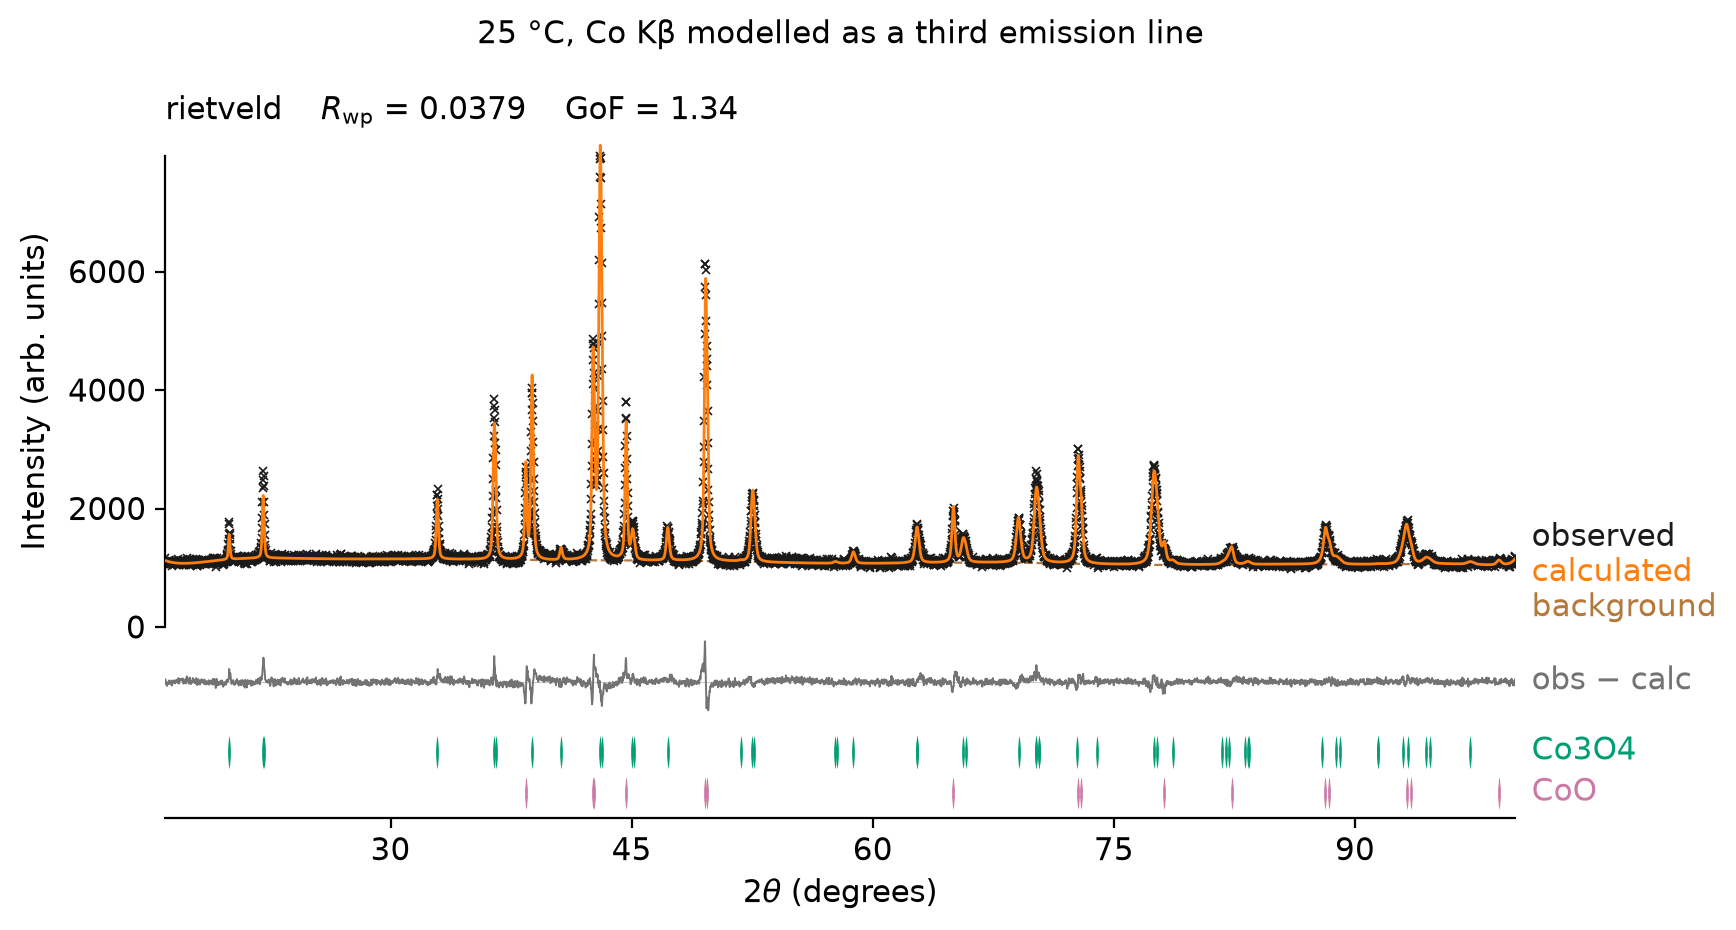

In [10]:
rx.viz.plot_result(res25, figsize=(10, 4.5), dpi=110, title="25 °C, Co Kβ modelled as a third emission line")

The two treatments agree within about 1 wt% and both agree with GSAS-II, but modelling Kβ fits the pattern much
better (GoF 1.3 against 2.0). Modelling Kβ uses the whole
pattern instead of throwing regions away. The refined Kβ weight is relative to Kα1 = 1 (with Kα2 = 0.5);
treat it as a nuisance parameter, since it also absorbs the f′ approximation and the detector's energy response.

The diagnostics on this single fit: `FLOOR_HIT` on some width terms (the data do not want them),
`HIGH_CORRELATION` between CoO's size and strain terms, which over this range look alike.

## 5. The series

`rx.SequentialRefinement` fits the scans in order, each warm-started from its predecessor. That is justified
here because this is a genuine ramp: one specimen, changing continuously. Following the series reference:

* `direction="both"` runs the chain forward and backward and flags parameters whose values depend on the
  order (`SEQUENTIAL_PATH_DEPENDENT`), the only check that separates a measurement from an ordering artefact.
* `verify_discontinuities=True` refits both sides of any flagged jump cold and independently.
* `constrain=` is the only way a tie reaches every pattern of a chain.
* `on_result=` keeps each pattern's full result, which we need for the per-pattern background check.

A first forward pass, to see what the series says about the plan:

In [11]:
first = rx.SequentialRefinement(make_structure(), make_instrument(patterns[0]))
series0 = first.fit(patterns, x=temps, x_label="T (°C)", labels=FOLDERS, plan=PLAN,
                    two_theta_limits=LIMITS, constrain=constrain)
for d in series0.diagnostics:
    if d.code == "SEQUENTIAL_PERSISTENT_FINDING":
        print(d.code, "|", d.message[:200])

SEQUENTIAL_PERSISTENT_FINDING | FLOOR_HIT fired on phases.0.lor_size in 9 of 12 patterns (75% of the series)
SEQUENTIAL_PERSISTENT_FINDING | FLOOR_HIT fired on phases.1.lor_strain in 8 of 12 patterns (67% of the series)


`SEQUENTIAL_PERSISTENT_FINDING`: `FLOOR_HIT` fires on the spinel's Lorentzian size term and on CoO's Lorentzian
strain term in most patterns. rietx's advice for a finding repeated across a series is to change the model, not
the individual fits: these two terms are not supported by the data, so we hold them at zero for every pattern
(the other width terms stay free). Then the full run, both directions:

In [12]:
def constrain_final(index, ref):
    constrain(index, ref)
    ref.hold(["phases.0.lor_size", "phases.1.lor_strain"])

results = {}
sr = rx.SequentialRefinement(make_structure(), make_instrument(patterns[0]))
series = sr.fit(patterns, x=temps, x_label="T (°C)", labels=FOLDERS, plan=PLAN, two_theta_limits=LIMITS,
                direction="both", verify_discontinuities=True, constrain=constrain_final,
                on_result=lambda i, r: results.__setitem__(i, r))
print(series.summary(deliverable="series"))

SeriesResult: 12 pattern(s), rietveld, direction=both
  diagnostics: 8 unresolved
    WARNING SEQUENTIAL_RWP_OUTLIER: pattern 6 (I20-880C) reached Rwp 0.0560 on its best rung, 1.11× the fence at 0.0503 (the reseed factor × the median Rwp of the patterns accepted before it), after every rung the chain tried (warm, warm_staged, cold); against I17-1000, the last pattern before it inside the fence: GoF 1.83 to its 1.49, Rexp 0.0307 to its 0.0306 — no starting point brought this fit near its neighbours', so the pattern itself differs from them; open its own fit before reading its values.  GoF says which way: well above theirs is a model the pattern has outgrown — a specimen change the model lacks, or a bad frame; like theirs, with a higher Rexp, is fewer counts — a short or blank frame, a weaker beam — where the fit may be sound, so check that each phase is still in the pattern (a scale within a few esds of zero is one it does not contain).  The fence follows the median of the accepted patt

### Reading the series diagnostics

The numpy `overflow encountered in matmul` warnings above come from inside rietx's solver during the run (they
are not rietx diagnostics). Every pattern still ends `converged`, as the table below shows, so they do not mark
any reported result; we leave them visible rather than silence them.

* **Ordering artefact: measured both ways, nothing disagrees.** No `SEQUENTIAL_PATH_DEPENDENT` and no
  `SEQUENTIAL_PATH_CHECK_INCOMPLETE`, so the trajectories do not depend on the direction of the chain.
  (Agreement is necessary, not sufficient: it compares two paths, not two basins.)
* **`SEQUENTIAL_DISCONTINUITY`, 880 → 1000 °C.** The spinel scale collapses and the CoO scale jumps.
  `verify_discontinuities` refitted both scans cold. For the spinel scale the cold pair reproduces the step
  (ratio 1.0): the transition is in the data. For the **CoO scale the ratio is 0**, which would normally mean
  "the chain made this step". Here it is a limitation of the check: a cold refit starts CoO at the CIF cell,
  4.26 Å, about 1.4 % short of its 1000 °C cell, outside the roughly 1 % a Rietveld fit can reach, so the cold
  fit cannot find the CoO peaks at all. Section 6 checks this directly.
* **`SEQUENTIAL_RWP_OUTLIER` at the first cooling scan (880 °C).** Every rung of the reseed ladder left it above
  the fence, with GoF up (1.8 against 1.5), so the model is missing something there. This scan is taken just after
  the 1000 °C hold, while CoO is re-oxidising; a specimen whose composition changes during the scan, or a
  re-forming spinel with a distribution of cells, cannot be described by two fixed phases. Read its values with
  that caveat.
* **`PHASE_UNCONSTRAINED`** appears on single patterns where a phase is absent (CoO at 880 °C on heating,
  Co3O4 at 1000 °C): those phases' cells and displacement parameters are not measurements there.
* The 2θ anchor: nothing in these scans pins the absolute angle at temperature. The zero comes from the 2008
  calibration and the sample displacement is refined per scan, so **absolute** cells carry that uncertainty;
  the shape of the trajectories is better determined than their absolute level.
* The other two discontinuities are in **width** terms (the spinel's strain broadening between 650 and 820 °C,
  CoO's size broadening between 350 and 650 °C), and the cold refits reproduce both (ratio about 1.0). The
  microstructure really changes as the spinel forms and grows; this is why the width terms are left free.

Per-pattern diagnostics and the background check (§4b QPA rule: read `worst_absorption` at every point of a
fraction trajectory, because an over-flexible background biases scales the same way at every point and
produces a smooth, wrong trajectory):

In [13]:
print(f"{'scan':10s}{'T':>6s}{'rung':>13s}{'Rwp':>8s}{'GoF':>6s}{'worst bkg absorption':>36s}   codes")
for e in series.entries:
    bg = rx.build_report(results[e.index]).background
    codes = sorted({d.code for d in e.diagnostics} - {"HOLD_BLOCKED_PLAN"})
    print(f"{e.label:10s}{e.x:6.0f}{e.rung:>13s}{e.statistics.rwp:8.4f}{e.statistics.gof:6.2f}"
          f"{bg.worst_absorption:8.3f} ({bg.worst_absorption_path:>24s})   {codes}")

scan           T         rung     Rwp   GoF                worst bkg absorption   codes
I2-25C        25         cold  0.0380  1.35   0.144 (   phases.0.atoms.0.biso)   ['FLOOR_HIT']
I5-350C      350         warm  0.0357  1.27   0.129 (   phases.0.atoms.0.biso)   ['FLOOR_HIT']
I8-650C      650         warm  0.0379  1.33   0.118 (   phases.0.atoms.0.biso)   []
I11-820C     820         warm  0.0425  1.47   0.085 (   phases.0.atoms.0.biso)   ['FLOOR_HIT']
I14-880C     880  warm_staged  0.0430  1.46   0.068 (   phases.0.atoms.0.biso)   ['FLOOR_HIT', 'PHASE_UNCONSTRAINED']
I17-1000    1000         warm  0.0457  1.49   0.044 (          phases.0.scale)   ['BISO_UNUSUALLY_LARGE', 'FLOOR_HIT', 'PHASE_UNCONSTRAINED']
I20-880C     880  warm_staged  0.0560  1.83   0.106 (   phases.0.atoms.0.biso)   ['BISO_NEGATIVE', 'FLOOR_HIT']
I23-840C     840         warm  0.0401  1.30   0.074 (   phases.0.atoms.0.biso)   ['FLOOR_HIT']
I26-820C     820         warm  0.0415  1.35   0.077 (   phases.0.atoms.0.bis

`worst_absorption` stays below 0.15 everywhere, well under the 0.25 at which rietx flags it, so the background is
not bending the scales. (`HOLD_BLOCKED_PLAN` is left out of the code column: it is the two holds doing their job
on every scan.) `BISO_NEGATIVE` on the cooling branch is on **CoO**, which is only 6 to 12 wt% there; section 6
tests whether it matters.

## 6. Three direct checks

In [14]:
# (a) 1000 °C, cold, with starting cells near the hot values (the check the cold verifier could not make)
ref_hot, res_hot = fit_one(patterns[5], structure=make_structure(a_spinel=8.23, a_rocksalt=4.32))
print("(a) 1000 °C cold refit from hot starting cells:", wt(res_hot), f"GoF {res_hot.statistics.gof:.2f}",
      "| chain:", {p.name: round(100 * p.weight_fraction, 2) for p in series.entries[5].qpa.phases})

# (b) the minor phase's B on the cooling branch: last scan, CoO Biso held at the spinel's value
last = results[11]
b_sp = next(p.value for p in last.parameters if p.path == "phases.0.atoms.0.biso")
b_co = next(p.value for p in last.parameters if p.path == "phases.1.atoms.0.biso")
ref_b = rx.Refinement(make_structure(), make_instrument(patterns[11])); constrain_final(0, ref_b)
ref_b.set_values({"phases.1.atoms.0.biso": b_sp})      # the O site follows through the tie
ref_b.hold(["phases.1.atoms.*.biso"])
res_b = ref_b.fit(patterns[11], plan=PLAN, two_theta_limits=LIMITS)
print(f"(b) 25 °C after cooling: chain (CoO B = {b_co:.2f} Å²)", {p.name: round(100*p.weight_fraction, 2) for p in series.entries[11].qpa.phases},
      f"| CoO B held at {b_sp:.2f} Å²:", wt(res_b))

# (c) the Kβ weight is a property of the tube and optics, so it should not move with temperature
kb = series.trajectory("instrument.source.lines.2.weight")
print("(c) Kβ weight along the series:", np.round(kb.value, 3))

(a) 1000 °C cold refit from hot starting cells: {'Co3O4': 0.0, 'CoO': 100.0} GoF 1.49 | chain: {'Co3O4': 0.0, 'CoO': 100.0}


(b) 25 °C after cooling: chain (CoO B = -2.06 Å²) {'Co3O4': 93.76, 'CoO': 6.24} | CoO B held at 0.71 Å²: {'Co3O4': 91.25, 'CoO': 8.75}
(c) Kβ weight along the series: [0.417 0.396 0.39  0.381 0.382 0.392 0.391 0.377 0.375 0.383 0.382 0.391]


* **(a)** Started near the hot cells, an independent cold fit at 1000 °C finds 100 % CoO, the same as the chain.
  The CoO step is real; the cold verifier's ratio of 0 came from its starting cell.
* **(b)** Holding CoO's B at the spinel's value instead of the refined, negative value moves the cooled specimen
  from about 94 to 91 wt% Co3O4. When CoO is a minor phase its B and its scale trade, and the data cannot settle
  B. Quote the cooling-branch fractions with a systematic of about ±3 wt% from this source, and do not quote the
  CoO B values there at all.
* **(c)** The Kβ weight is constant within about 5 % across all twelve scans, as an instrument property should
  be, which supports the Kβ model.

## 7. Trajectories

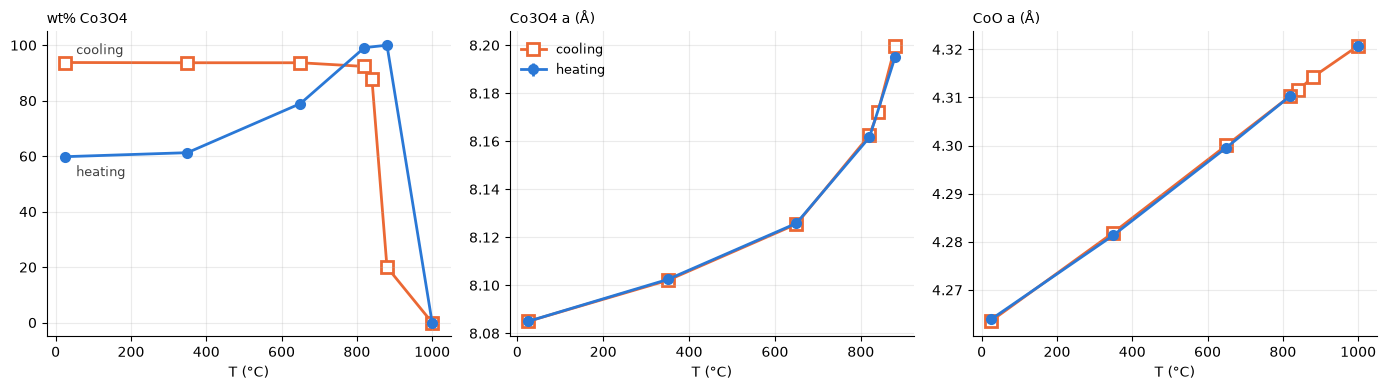

In [15]:
idx_heat = [i for i in range(len(temps)) if i <= 5]          # 25 -> 1000 °C, including the 1000 °C point
idx_cool = [i for i in range(len(temps)) if i >= 5]          # 1000 -> 25 °C
entries = series.entries

def frac(e, name):
    return next(100 * p.weight_fraction for p in e.qpa.phases if p.name == name) if e.qpa else np.nan

def cell(e, i):
    unconstrained = any(d.code == "PHASE_UNCONSTRAINED" and any(f"phases.{i}" in w for w in d.where)
                        for d in e.diagnostics)
    p = next((p for p in e.parameters if p.path == f"phases.{i}.cell.a"), None)
    present = frac(e, ("Co3O4", "CoO")[i]) > 0.5
    return (p.value, p.stderr or 0) if (p and present and not unconstrained) else (np.nan, 0)

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
panels = [("wt% Co3O4", lambda e: (frac(e, "Co3O4"), 0)),
          ("Co3O4 a (Å)", lambda e: cell(e, 0)),
          ("CoO a (Å)", lambda e: cell(e, 1))]
styles = [(idx_cool, COOLING, "s", "white", "cooling", 1),       # open squares underneath
          (idx_heat, HEATING, "o", HEATING, "heating", 2)]       # filled circles on top
for k, (ax, (title, get)) in enumerate(zip(axes, panels)):
    for idx, color, marker, face, label, z in styles:
        x = np.array([temps[i] for i in idx]); y, e = map(np.array, zip(*[get(entries[i]) for i in idx]))
        ax.errorbar(x, y, yerr=e, color=color, marker=marker, ms=9 if marker == "s" else 6, mfc=face, mew=2,
                    lw=2, capsize=0, label=label, zorder=z)
        if k == 0:                                               # direct labels where the branches separate
            ax.annotate(label, (x[0] if label == "heating" else x[-1], y[0] if label == "heating" else y[-1]),
                        textcoords="offset points", xytext=(8, -14 if label == "heating" else 6), color="0.25", fontsize=9)
    ax.set_title(title, fontsize=10, loc="left"); ax.set_xlabel("T (°C)")
    ax.spines[["top", "right"]].set_visible(False); ax.grid(alpha=0.25)
axes[1].legend(frameon=False, fontsize=9, loc="upper left")
plt.tight_layout()

In [16]:
print(f"{'scan':10s}{'T (°C)':>7s}{'wt% Co3O4':>11s}{'wt% CoO':>9s}{'a Co3O4 (Å)':>14s}{'a CoO (Å)':>12s}{'displ. (mm)':>13s}")
for e in entries:
    a1, a2 = cell(e, 0)[0], cell(e, 1)[0]
    disp = next(p.value for p in e.parameters if p.path == "instrument.geometry.sample_displacement")
    print(f"{e.label:10s}{e.x:7.0f}{frac(e, 'Co3O4'):11.1f}{frac(e, 'CoO'):9.1f}"
          f"{'' if np.isnan(a1) else f'{a1:.4f}':>14s}{'' if np.isnan(a2) else f'{a2:.4f}':>12s}{disp:13.3f}")
series.write_csv("co3o4_series.csv")

scan       T (°C)  wt% Co3O4  wt% CoO   a Co3O4 (Å)   a CoO (Å)  displ. (mm)
I2-25C         25       59.8     40.2        8.0850      4.2639        0.049
I5-350C       350       61.3     38.7        8.1024      4.2814       -0.070
I8-650C       650       79.0     21.0        8.1258      4.2996       -0.219
I11-820C      820       99.1      0.9        8.1616      4.3103       -0.302
I14-880C      880      100.0      0.0        8.1951                   -0.339
I17-1000     1000        0.0    100.0                    4.3207       -0.557
I20-880C      880       20.0     80.0        8.1996      4.3143       -0.520
I23-840C      840       87.8     12.2        8.1722      4.3115       -0.414
I26-820C      820       92.3      7.7        8.1625      4.3103       -0.403
I29-650C      650       93.7      6.3        8.1255      4.3000       -0.328
I32-350C      350       93.7      6.3        8.1020      4.2819       -0.193
I35-25C        25       93.8      6.2        8.0850      4.2635       -0.076

What the trajectories show:

* **Heating**: the starting specimen is about 60 % Co3O4 / 40 % CoO. CoO oxidises to spinel between 350 and
  820 °C, and the specimen is all spinel by 820 to 880 °C. At 1000 °C the spinel has decomposed completely to
  rock-salt CoO.
* **Cooling**: CoO re-oxidises, but only to about 94 % Co3O4 (about 91 % if CoO's B is held, section 6b). The reaction is fastest just below the
  decomposition temperature (20 % at 880 °C, 88 % at 840 °C) and then essentially stops. The cooled specimen
  is not the starting one: the hysteresis is the point of the experiment.
* **Lattice parameters** rise smoothly with temperature and retrace on cooling. Over 25 to 820 °C on heating the mean
  linear expansion is about 1.2 × 10⁻⁵ K⁻¹ for Co3O4 and 1.4 × 10⁻⁵ K⁻¹ for CoO (from the table above). Treat that as approximate: the
  sample displacement drifts by about 0.6 mm over the run (the hot stage moves the specimen), and nothing in
  the scans pins the absolute 2θ at temperature.

## 8. Against the GSAS-II refinements in the folder

In [17]:
gsas_runs = {0: DATA / "I2-25C" / "test.lst", 4: DATA / "I14-880C" / "test.lst", 5: DATA / "I17-1000" / "example.lst"}
print(f"{'scan':10s}{'':9s}{'wt% Co3O4':>10s}{'a Co3O4':>10s}{'a CoO':>9s}{'GoF':>6s}   GSAS-II excluded regions")
for i, path in gsas_runs.items():
    g = read_lst(path)
    sp = next(v for k, v in g["phases"].items() if k.startswith("Co3"))
    rs = next(v for k, v in g["phases"].items() if k.startswith("Co O"))
    e = entries[i]
    a1, a2 = cell(e, 0)[0], cell(e, 1)[0]
    print(f"{e.label:10s}{'rietx':9s}{frac(e, 'Co3O4'):10.1f}{a1:10.4f}{a2:9.4f}{e.statistics.gof:6.2f}")
    print(f"{'':10s}{'GSAS-II':9s}{100*sp['weight_fraction']:10.1f}{sp.get('a', np.nan):10.4f}"
          f"{rs.get('a', np.nan):9.4f}{g['gof']:6.2f}   {len(g['excluded_regions'])}")

scan                wt% Co3O4   a Co3O4    a CoO   GoF   GSAS-II excluded regions
I2-25C    rietx          59.8    8.0850   4.2639  1.35
          GSAS-II        59.6    8.0889   4.2661  2.36   5
I14-880C  rietx         100.0    8.1951      nan  1.46
          GSAS-II        99.9    8.1947      nan  4.83   0
I17-1000  rietx           0.0       nan   4.3207  1.49
          GSAS-II        99.0    8.2301   4.4004  7.90   0


* **25 °C**: fractions agree within 1 wt%. GSAS-II's spinel cell is 0.004 Å larger; it refined no sample
  displacement and used a slightly different wavelength (1.78892 against 1.78901 Å), both of which move an
  absolute cell at this level.
* **880 °C (heating)**: both say essentially pure spinel, and the cells agree to 0.0004 Å. GSAS-II's GOF of 4.8
  comes from the Kβ lines it neither modelled nor excluded in this refinement.
* **1000 °C**: the GSAS-II file reports **99 % Co3O4** with a = 8.230 Å, and CoO at a = 4.40 Å with an esd 100
  times larger than usual. The pattern contains no spinel (section 6a, and the plot above): that refinement is
  stuck in a wrong solution, which its GOF of 7.9 and Durbin-Watson of 0.04 also signal. Some of the
  "unexplained" peaks it was trying to fit are the CoO Kβ lines.

The cycle as a whole reproduces the older heating/cooling figure in the data folder
(`Co-O phases heating vs cooling.jpg`) point for point, with one addition: the first cooling scan at 880 °C
(about 20 % Co3O4), which that figure does not show.

## Summary

| Step | rietx diagnostic or check | Outcome |
|---|---|---|
| Radiation | file titles, GSAS-II wavelengths, implied spinel cell | Co Kα |
| `.prm` | refused: non-zero `trns`; `GSAS_PRM_GEOMETRY_ASSUMED` | transparency zeroed in a temporary copy; Bragg-Brentano rebuilt |
| "Impurity" peaks | Kβ positions inside every excluded region | Co Kβ modelled as an emission line |
| Kβ and Co's absorption edge | refused: f′ differs by 2.5 e | f′ override at the primary line |
| Width terms | `SEQUENTIAL_PERSISTENT_FINDING` (`FLOOR_HIT`) | two unsupported terms held at zero |
| Ordering | `direction="both"`: nothing path-dependent | trajectories are not chain artefacts |
| 880 → 1000 °C step | `SEQUENTIAL_DISCONTINUITY`; cold check limited by starting cell | confirmed by a direct cold refit |
| First cooling scan | `SEQUENTIAL_RWP_OUTLIER` | quoted with a caveat (specimen changing) |
| Background | `worst_absorption` < 0.15 at every point | fractions not bent by the background |
| Minor-phase B (cooling) | `BISO_NEGATIVE` on CoO; holding it moves 94 → 91 wt% | ±3 wt% systematic on cooling fractions |

The full table is written to `co3o4_series.csv`.

In [18]:
print(series.provenance)

Provenance
  package_version: '1.9.0'
  schema_version: '0.55'
  backend: 'numpy'
  dtype: 'float64'
  solver: 'lm'
  report_thresholds_version: '1.12'
  created_utc: '2026-10-23T22:02:19Z'
